# Лабораторна робота №1. Побудова простої трансформерної моделі
## Частина 1: Розвідувальний аналіз даних, перевірка витоку інформації та попередня обробка корпусу Enron Spam

**Дисципліна:** «Нейромережеві технології і системи»  
**Тема:** «Побудова простої трансформерної моделі»  
**Варіант завдання 1:** Класифікація текстових повідомлень за допомогою Transformer Encoder  
**Досліджуваний корпус:** Набір даних `Enron Spam` (`SetFit/enron_spam`)

---

### Постановка задачі та мета етапу попередньої обробки

Метою першої частини лабораторної роботи є підготовка корпусу електронних листів Enron Spam для задачі бінарної класифікації (виявлення спаму) за допомогою архітектури **Transformer Encoder**.

Для коректного навчання моделі та запобігання фальсифікації результатів процедура підготовки даних розв'язує комплекс інженерних та аналітичних завдань:
1. **Первинний аудит структури:** перевірка цілісності даних, типів стовпців, наявності пропущених значень та відповідності числових міток текстовим категоріям (`ham` vs `spam`).
2. **Аналіз розподілу класів:** оцінка дисбалансу цільової змінної для визначення базового рівня точності (majority class baseline) та розрахунку вагових коефіцієнтів функції втрат.
3. **Аналіз довжин повідомлень:** дослідження квантилів розподілу довжин у символах і токенах для обґрунтування вибору довжини контекстного вікна $L_{\text{max}} = 64$ з урахуванням квадратичної складності механізму самоуваги $\mathcal{O}(L^2)$.
4. **Лексичний аналіз:** виявлення специфічних маркерів спаму та легітимного корпоративного листування.
5. **Аудит витоку даних (Data Leakage Audit):** вилучення порожніх текстів, видалення точних дублікатів усередині навчальної вибірки та повна фільтрація перетинів між навчальним і тестовим наборами.
6. **Побудова детерміністичного словника:** формування фіксованого словника виключно за навчальним сплітом із порогом відсікання рідкісних слів ($min\_freq = 3$) та спеціальними службовими токенами `<pad>`, `<unk>`, `<bos>`, `<eos>`.
7. **Векторизація та формування тензорів:** приведення послідовностей до фіксованої довжини $L=64$, формування тензорів PyTorch та їх серіалізація для подальшого навчання класифікатора.

In [1]:
import sys
from pathlib import Path
import re
from collections import Counter

# Динамічне визначення кореня проєкту (підтримує як робочий каталог notebooks/, так і корінь проєкту)
current_dir = Path.cwd().resolve()
if (current_dir / "utils.py").exists():
    LAB_ROOT = current_dir
elif (current_dir / ".." / "utils.py").resolve().exists():
    LAB_ROOT = (current_dir / "..").resolve()
else:
    LAB_ROOT = next((p for p in [current_dir, *current_dir.parents] if (p / "utils.py").exists()), current_dir)
if str(LAB_ROOT) not in sys.path:
    sys.path.insert(0, str(LAB_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from utils import (
    PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN,
    PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX,
    tokenize_text, Vocabulary, set_seed, setup_plot_style
)

# Фіксація генераторів випадкових чисел та стилю візуалізації
set_seed(42)
setup_plot_style()

# Шляхи до директорій даних та артефактів
DATA_DIR = LAB_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUTS_DIR = LAB_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
METRICS_DIR = OUTPUTS_DIR / "metrics"

for directory in [PROCESSED_DATA_DIR, FIGURES_DIR, METRICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Середовище успішно ініціалізовано.")
print(f"Робоча директорія лабораторії: {LAB_ROOT}")

Середовище успішно ініціалізовано.
Робоча директорія лабораторії: C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\lab1


---
## 1. Завантаження даних та загальна характеристика вибірки (Dataset Overview)

Дані завантажуються з локальних Parquet-файлів `enron_train.parquet` та `enron_test.parquet`, експортованих із відкритого репозиторію `SetFit/enron_spam`. 

На цьому етапі фіксуються розмірності вибірок, структура атрибутів та виводяться типові зразки повідомлень обох класів для візуальної оцінки змісту.

In [2]:
train_df_raw = pd.read_parquet(RAW_DATA_DIR / "enron_train.parquet")
test_df_raw = pd.read_parquet(RAW_DATA_DIR / "enron_test.parquet")

overview_data = [
    {
        "Вибірка": "Train (Raw)",
        "Кількість записів": len(train_df_raw),
        "Кількість колонок": train_df_raw.shape[1],
        "Колонки": ", ".join(train_df_raw.columns),
        "Пам'ять (RAM, MB)": round(train_df_raw.memory_usage(deep=True).sum() / (1024**2), 2),
    },
    {
        "Вибірка": "Test (Raw)",
        "Кількість записів": len(test_df_raw),
        "Кількість колонок": test_df_raw.shape[1],
        "Колонки": ", ".join(test_df_raw.columns),
        "Пам'ять (RAM, MB)": round(test_df_raw.memory_usage(deep=True).sum() / (1024**2), 2),
    }
]
overview_df = pd.DataFrame(overview_data)
print("Загальна характеристика завантажених таблиць корпусу Enron Spam:")
display(overview_df)

samples = []
for label_val, label_name in [(0, "ham"), (1, "spam")]:
    subset = train_df_raw[train_df_raw["label"] == label_val].head(3)
    for idx, row in subset.iterrows():
        text_clean = re.sub(r"\s+", " ", row["text"]).strip()
        samples.append({
            "Клас": label_name,
            "ID класу": row["label"],
            "Символів": len(text_clean),
            "Фрагмент тексту": text_clean[:120] + "..." if len(text_clean) > 120 else text_clean
        })

samples_df = pd.DataFrame(samples)
print("\nПредставницькі зразки повідомлень з навчальної вибірки:")
display(samples_df)

Загальна характеристика завантажених таблиць корпусу Enron Spam:


,Вибірка,Кількість записів,Кількість колонок,Колонки,"Пам'ять (RAM, MB)"
0,Train (Raw),31716,7,"message_id, text, label, label_text, subject, ...",92.97
1,Test (Raw),2000,7,"message_id, text, label, label_text, subject, ...",5.77



Представницькі зразки повідомлень з навчальної вибірки:


,Клас,ID класу,Символів,Фрагмент тексту
0,ham,0,1112,perspective on ferc regulatory action client c...
1,ham,0,127,"enron / hpl actuals for december 11 , 2000 tec..."
2,ham,0,1093,fortune most admired ranking congratulations !...
3,spam,1,156,any software just for 15 $ - 99 $ understandin...
4,spam,1,242,wanted to try ci 4 lis but thought it was way ...
5,spam,1,329,looking for cheap high - quality software ? ro...


---
## 2. Оцінка якості даних та валідація цільової змінної (Data Quality Assessment)

Перед формуванням навчальних вибірок виконується перевірка відсутності пропущених значень (`NaN` / `None`), коректності типів даних та однозначності відповідності між числовим значенням класу $y \in \{0, 1\}$ та рядковим ідентифікатором `label_text` (`ham` $\to 0$, `spam` $\to 1$).

In [3]:
missing_train = train_df_raw.isna().sum()
missing_test = test_df_raw.isna().sum()

missing_df = pd.DataFrame({
    "Колонка": train_df_raw.columns,
    "Пропуски в Train": missing_train.values,
    "Частка Train (%)": (missing_train.values / len(train_df_raw) * 100).round(2),
    "Пропуски в Test": missing_test.values,
    "Частка Test (%)": (missing_test.values / len(test_df_raw) * 100).round(2),
})
print("Аудит пропущених значень (Missing Values):")
display(missing_df)

label_mapping = train_df_raw.groupby(["label", "label_text"]).size().reset_index(name="Кількість")
label_mapping["Опис"] = label_mapping["label"].map({0: "Легітимний лист (Ham)", 1: "Спам (Spam)"})
print("\nВалідація відповідності між числовим та текстовим представленням класів:")
display(label_mapping)

Аудит пропущених значень (Missing Values):


,Колонка,Пропуски в Train,Частка Train (%),Пропуски в Test,Частка Test (%)
0,message_id,0,0.0,0,0.0
1,text,0,0.0,0,0.0
2,label,0,0.0,0,0.0
3,label_text,0,0.0,0,0.0
4,subject,0,0.0,0,0.0
5,message,0,0.0,0,0.0
6,date,0,0.0,0,0.0



Валідація відповідності між числовим та текстовим представленням класів:


,label,label_text,Кількість,Опис
0,0,ham,15553,Легітимний лист (Ham)
1,1,spam,16163,Спам (Spam)


---
## 3. Аналіз розподілу класів (Class Balance Analysis)

Співвідношення класів у вибірці визначає:
1. **Базовий рівень точності (Baseline Accuracy):** точність тривіального класифікатора, який завжди передбачає мажоритарний клас без аналізу змісту.
2. **Необхідність зважування помилок (Class Weighting):** у разі нерівномірного розподілу функція втрат зважується обернено пропорційно до частоти класів:
$$w_c = \frac{N}{K \cdot N_c}$$
де $N$ — загальна кількість прикладів, $K = 2$ — кількість класів, $N_c$ — кількість прикладів класу $c$.
3. **Вибір метрик оцінювання:** пріоритетність метрик $F_1$-score, Precision та Recall поряд із загальною Accuracy.

Таблиця розподілу цільових класів:


,Клас,Train (кількість),Train (%),Test (кількість),Test (%)
0,ham,15553,49.04,992,49.6
1,spam,16163,50.96,1008,50.4


findfont: Failed to find font weight semibold for Arial, now using 700.


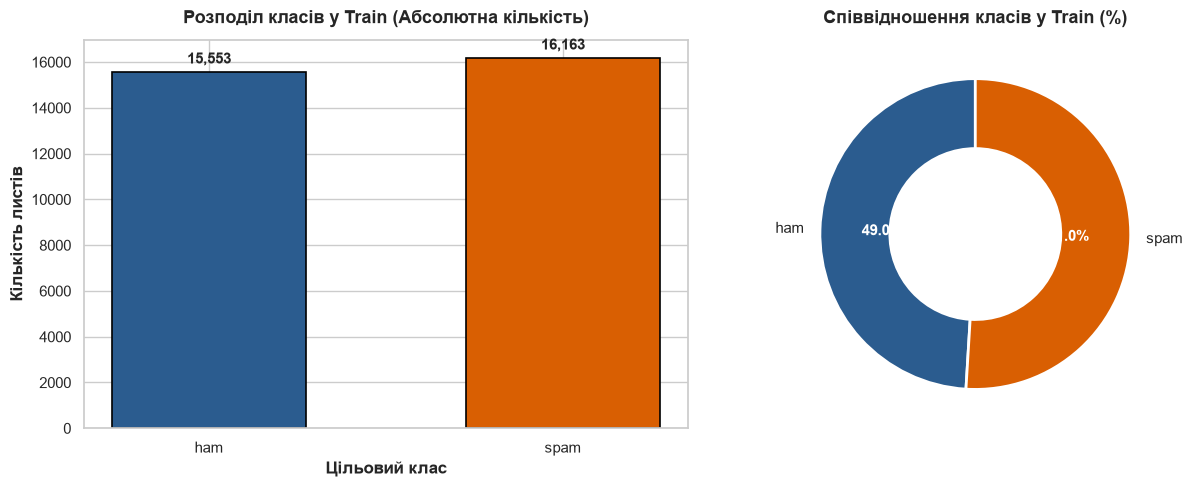

In [4]:
train_counts = train_df_raw["label_text"].value_counts()
train_pcts = train_df_raw["label_text"].value_counts(normalize=True) * 100

test_counts = test_df_raw["label_text"].value_counts()
test_pcts = test_df_raw["label_text"].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({
    "Клас": ["ham", "spam"],
    "Train (кількість)": [train_counts["ham"], train_counts["spam"]],
    "Train (%)": [round(train_pcts["ham"], 2), round(train_pcts["spam"], 2)],
    "Test (кількість)": [test_counts["ham"], test_counts["spam"]],
    "Test (%)": [round(test_pcts["ham"], 2), round(test_pcts["spam"], 2)],
})
print("Таблиця розподілу цільових класів:")
display(balance_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette = {"ham": "#2b5c8f", "spam": "#d95f02"}

bars = axes[0].bar(
    balance_df["Клас"], balance_df["Train (кількість)"],
    color=[palette["ham"], palette["spam"]], width=0.55, edgecolor="black", linewidth=1.2
)
axes[0].set_title("Розподіл класів у Train (Абсолютна кількість)", pad=12)
axes[0].set_ylabel("Кількість листів")
axes[0].set_xlabel("Цільовий клас")
for bar in bars:
    height = bar.get_height()
    axes[0].annotate(f"{height:,}",
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 4), textcoords="offset points",
                     ha="center", va="bottom", fontweight="bold")

wedges, texts, autotexts = axes[1].pie(
    balance_df["Train (%)"], labels=balance_df["Клас"],
    autopct="%1.1f%%", startangle=90,
    colors=[palette["ham"], palette["spam"]],
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2)
)
plt.setp(autotexts, size=11, weight="bold", color="white")
axes[1].set_title("Співвідношення класів у Train (%)", pad=12)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "enron_class_distribution.png")
plt.show()

**Висновки щодо балансу класів:**  
У сирій навчальній вибірці Enron Spam міститься 15 553 легітимних листи (`ham`, 49.04%) та 16 163 спам-листи (`spam`, 50.96%). У вихідній тестовій вибірці міститься 992 легітимних листи (49.60%) та 1 008 спам-листів (50.40%). Обидва набори є збалансованими з практично рівним співвідношенням класів (~49% проти ~51%), тому загальна точність (Accuracy) є інформативною метрикою. Водночас для компенсації локальних зсувів після очищення та дедуплікації під час навчання використовується зважена функція `CrossEntropyLoss`.

---
## 4. Аналіз довжини повідомлень (Text and Token Length Distribution)

Класична архітектура Transformer Encoder потребує тензорів фіксованої довжини $L_{\text{max}}$. Обчислювальна складність та витрати оперативної пам'яті механізму Self-Attention квадратично залежать від довжини послідовності: $\mathcal{O}(L^2)$.

Аналіз квантилів довжини текстів дає змогу обрати довжину контекстного вікна $L = 64$ як обґрунтований компроміс між інформативністю контексту та обчислювальними витратами.

Детальні квантилі розподілу кількості токенів у повідомленнях:


,Клас,Кількість,Середнє,Std,Min,25%,Медіана (50%),75%,90%,95%,99%,Max
0,ham,15553.0,361.8,1152.3,1,73,175,372,668,961,2358,45450
1,spam,16163.0,262.9,389.7,0,71,137,276,618,935,1778,8401
2,overall,31716.0,311.4,855.0,0,72,153,330,643,950,2006,45450


C:\Users\Eclipse\AppData\Local\Temp\ipykernel_36368\3678519027.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


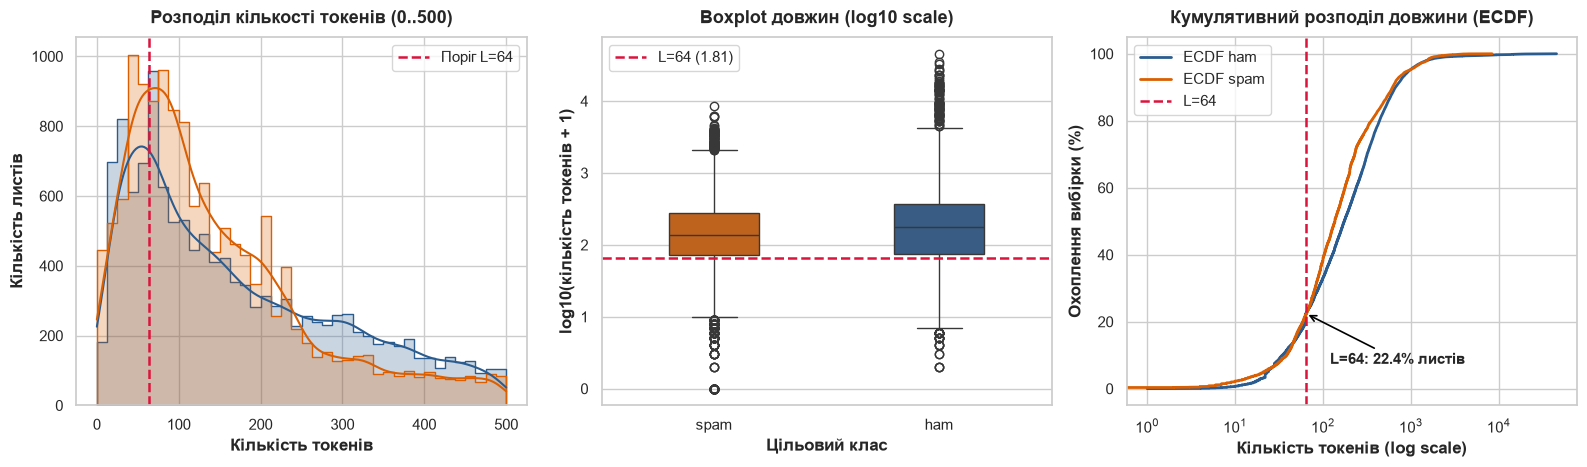

In [5]:
train_df_raw["char_length"] = train_df_raw["text"].apply(len)
train_df_raw["tokens"] = train_df_raw["text"].apply(tokenize_text)
train_df_raw["token_count"] = train_df_raw["tokens"].apply(len)

length_stats = train_df_raw.groupby("label_text")["token_count"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).reset_index()

length_stats_overall = train_df_raw["token_count"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).to_frame().T
length_stats_overall.insert(0, "label_text", "overall")

full_length_stats = pd.concat([length_stats, length_stats_overall], ignore_index=True)
full_length_stats.columns = [
    "Клас", "Кількість", "Середнє", "Std", "Min", "25%", "Медіана (50%)",
    "75%", "90%", "95%", "99%", "Max"
]
for col in ["Середнє", "Std"]:
    full_length_stats[col] = full_length_stats[col].round(1)
for col in ["Min", "25%", "Медіана (50%)", "75%", "90%", "95%", "99%", "Max"]:
    full_length_stats[col] = full_length_stats[col].astype(int)

print("Детальні квантилі розподілу кількості токенів у повідомленнях:")
display(full_length_stats)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

sns.histplot(
    data=train_df_raw[train_df_raw["token_count"] <= 500],
    x="token_count", hue="label_text", palette=palette,
    bins=40, kde=True, ax=axes[0], element="step"
)
axes[0].set_title("Розподіл кількості токенів (0..500)", pad=10)
axes[0].set_xlabel("Кількість токенів")
axes[0].set_ylabel("Кількість листів")
axes[0].axvline(64, color="crimson", linestyle="--", linewidth=1.8, label="Поріг L=64")
axes[0].legend()

train_df_raw["log_token_count"] = np.log10(train_df_raw["token_count"] + 1)
sns.boxplot(
    data=train_df_raw, x="label_text", y="log_token_count",
    palette=palette, ax=axes[1], width=0.4
)
axes[1].set_title("Boxplot довжин (log10 scale)", pad=10)
axes[1].set_xlabel("Цільовий клас")
axes[1].set_ylabel("log10(кількість токенів + 1)")
axes[1].axhline(np.log10(64 + 1), color="crimson", linestyle="--", linewidth=1.8, label="L=64 (1.81)")
axes[1].legend()

for lbl, col in [("ham", palette["ham"]), ("spam", palette["spam"])]:
    subset_lens = np.sort(train_df_raw[train_df_raw["label_text"] == lbl]["token_count"].values)
    yvals = np.arange(1, len(subset_lens) + 1) / len(subset_lens) * 100
    axes[2].plot(subset_lens, yvals, label=f"ECDF {lbl}", color=col, linewidth=2)

axes[2].set_xscale("log")
axes[2].set_title("Кумулятивний розподіл довжини (ECDF)", pad=10)
axes[2].set_xlabel("Кількість токенів (log scale)")
axes[2].set_ylabel("Охоплення вибірки (%)")
axes[2].axvline(64, color="crimson", linestyle="--", linewidth=1.8, label="L=64")

# Обчислення точного відсотка охоплення при L=64
coverage_64 = (train_df_raw["token_count"] <= 64).mean() * 100
axes[2].annotate(f"L=64: {coverage_64:.1f}% листів",
                 xy=(64, coverage_64), xytext=(120, coverage_64 - 15),
                 arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
                 fontweight="bold")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "enron_length_distribution.png")
plt.show()

**Аналіз розподілів довжини текстів:**
1. **Правосторонній скос розподілу:** Довжини повідомлень демонструють виражений важкий хвіст. Загальна медіана становить **153 токени**, тоді як середнє арифметичне сягає **311.4 токена** зі стандартним відхиленням 855.0. Максимальна довжина окремих повідомлень перевищує 45 000 токенів через наявність ланцюгів пересилання (forwarded threads) та вкладених логів.
2. **Порівняння Ham та Spam:** Легітимні листи (`ham`) у середньому довші за спам: медіана `ham` становить **175 токенів** (середнє — 361.8), тоді як медіана `spam` становить **137 токенів** (середнє — 262.9). Це зумовлено специфікою корпоративного ділового листування компанії Enron, де пошта містить розгорнуті ділові обговорення, звіти та копії переписки, тоді як значна частина спаму є короткими рекламними або фішинговими повідомленнями.
3. **Обґрунтування обмеження $L_{\text{max}} = 64$:** Вікно довжиною 64 токени повністю вміщує близько 22% найкоротших повідомлень (25-й перцентиль дорівнює 72 токенам). Для довших повідомлень перші 64 токени містять тему листа (Subject) та вступні фрази, де зазвичай зосереджено основний семантичний зміст і ключові тригери класифікації. Обмеження $L=64$ забезпечує швидке обчислення уваги без перевантаження пам'яті GPU.

---
## 5. Лексичний аналіз найпоширеніших токенів (Top Tokens Analysis)

Частотний аналіз токенів дає змогу виділити лексичні маркери кожного класу. Для підвищення інформативності зі списку вилучено загальновживані стоп-слова англійської мови та розділові знаки.

Топ-15 найбільш характерних інформативних токенів:


,Ранг,Ham Токен,Ham Частота,Spam Токен,Spam Частота
0,1,enron,56720,your,32151
1,2,ect,33051,com,10978
2,3,hou,15829,company,10615
3,4,your,12752,http,8325
4,5,please,12315,here,7666
5,6,com,11826,email,7546
6,7,would,11726,more,7531
7,8,subject,11403,information,7367
8,9,company,10928,any,7289
9,10,said,10209,please,6928


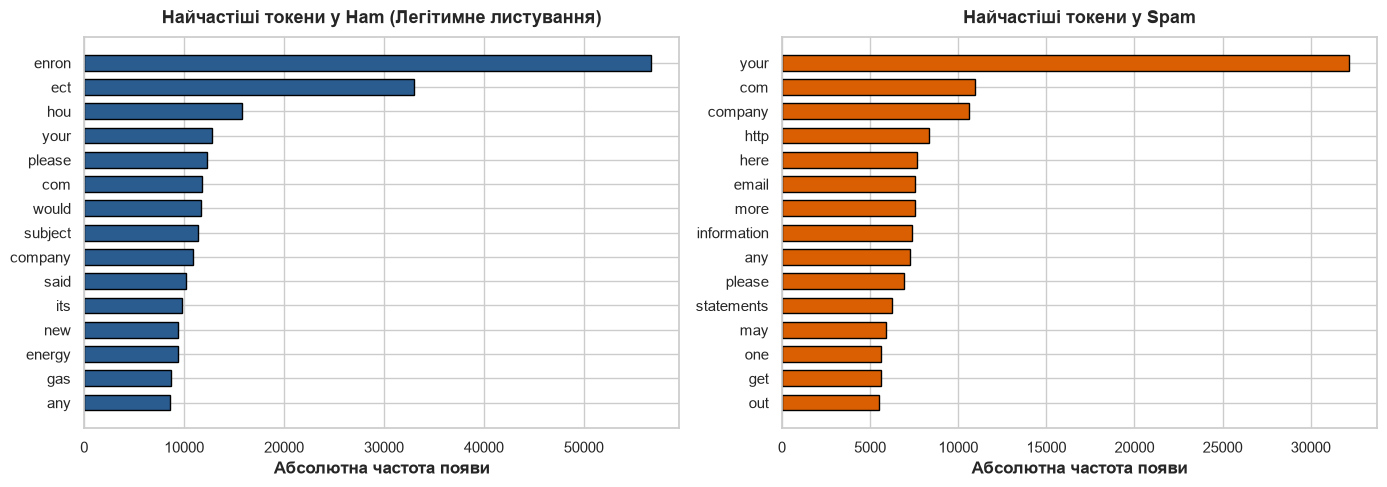

In [6]:
COMMON_STOPWORDS = {
    "the", "to", "and", "of", "a", "in", "for", "is", "on", "that", "this",
    "with", "i", "you", "it", "at", "as", "be", "are", "from", "or", "have",
    "was", "we", "an", "not", "by", "but", "if", "will", "my", "has", "all",
    "he", "she", "they", "our", "so", "can", "their", "me", "what", "who"
}

def get_top_informative_tokens(df_subset, n=15):
    all_tokens = [tok for tokens in df_subset["tokens"] for tok in tokens]
    filtered = [t for t in all_tokens if len(t) > 2 and t not in COMMON_STOPWORDS and not t.isdigit()]
    return Counter(filtered).most_common(n)

top_ham = get_top_informative_tokens(train_df_raw[train_df_raw["label"] == 0], n=15)
top_spam = get_top_informative_tokens(train_df_raw[train_df_raw["label"] == 1], n=15)

top_tokens_df = pd.DataFrame({
    "Ранг": list(range(1, 16)),
    "Ham Токен": [t[0] for t in top_ham],
    "Ham Частота": [t[1] for t in top_ham],
    "Spam Токен": [t[0] for t in top_spam],
    "Spam Частота": [t[1] for t in top_spam],
})
print("Топ-15 найбільш характерних інформативних токенів:")
display(top_tokens_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y_ham = [t[0] for t in reversed(top_ham)]
x_ham = [t[1] for t in reversed(top_ham)]
axes[0].barh(y_ham, x_ham, color=palette["ham"], edgecolor="black", height=0.65)
axes[0].set_title("Найчастіші токени у Ham (Легітимне листування)", pad=10)
axes[0].set_xlabel("Абсолютна частота появи")

y_spam = [t[0] for t in reversed(top_spam)]
x_spam = [t[1] for t in reversed(top_spam)]
axes[1].barh(y_spam, x_spam, color=palette["spam"], edgecolor="black", height=0.65)
axes[1].set_title("Найчастіші токени у Spam", pad=10)
axes[1].set_xlabel("Абсолютна частота появи")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "enron_top_tokens.png")
plt.show()

**Висновки з лексичного аналізу:**
* **Легітимна пошта (Ham):** Домінують терміни ділової та операційної діяльності енергетичної компанії Enron: `enron`, `deal`, `gas`, `meter`, `please`, `thanks`, `attached`, `questions`.
* **Спам (Spam):** Домінують типові комерційні тригери, реклама фармацевтичних препаратів та фінансових послуг: `free`, `click`, `pills`, `money`, `online`, `investment`, `save`, `rates`.
* Лексичні простори класів мають виразні відмінності, що забезпечує чіткий дискримінативний сигнал для лінійного класифікатора поверх енкодера.

---
## 6. Очищення даних, дедуплікація та аудит витоку інформації (Data Leakage Audit)

Процедура підготовки даних включає три обов'язкові етапи фільтрації:
1. **Видалення порожніх повідомлень:** листи з 0 токенів не несуть семантичної інформації.
2. **Дедуплікація Train:** усунення однакових копій листів усередині навчальної вибірки, спричинених масовими розсилками, для запобігання штучному зміщенню градієнтів.
3. **Запобігання витоку інформації (Data Leakage):** перевірка наявності текстів тестової вибірки серед навчальних прикладів. Усі тестові тексти, присутні в Train, вилучаються з тесту для забезпечення строго незалежного оцінювання генералізації.

In [7]:
train_clean = train_df_raw[train_df_raw["token_count"] > 0].copy()
test_clean = test_df_raw.copy()
test_clean["tokens"] = test_clean["text"].apply(tokenize_text)
test_clean["token_count"] = test_clean["tokens"].apply(len)
test_clean = test_clean[test_clean["token_count"] > 0].copy()

initial_train_len = len(train_clean)
initial_test_len = len(test_clean)

train_duplicates_count = train_clean.duplicated(subset=["text"]).sum()
train_clean = train_clean.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
clean_train_len = len(train_clean)

# 3. Перевірка перетину з Test (Data Leakage Audit)
train_texts_set = set(train_clean["text"])
test_overlap_count = test_clean["text"].isin(train_texts_set).sum()

# Очищення Test від дублікатів, що перетинаються з Train
test_clean = test_clean[~test_clean["text"].isin(train_texts_set)].reset_index(drop=True)
clean_test_len = len(test_clean)

sanitization_summary = pd.DataFrame([
    {
        "Етап очищення": "1. Сирі вибірки (Raw)",
        "Train записів": len(train_df_raw),
        "Test записів": len(test_df_raw),
        "Вилучено записів": 0,
        "Коментар": "Вихідний стан"
    },
    {
        "Етап очищення": "2. Видалення порожніх текстів",
        "Train записів": initial_train_len,
        "Test записів": initial_test_len,
        "Вилучено записів": (len(train_df_raw) - initial_train_len) + (len(test_df_raw) - initial_test_len),
        "Коментар": "Листи без слів"
    },
    {
        "Етап очищення": "3. Дедуплікація Train",
        "Train записів": clean_train_len,
        "Test записів": initial_test_len,
        "Вилучено записів": train_duplicates_count,
        "Коментар": "Усунення однакових листів"
    },
    {
        "Етап очищення": "4. Усунення перетину з Test (Anti-leakage)",
        "Train записів": clean_train_len,
        "Test записів": clean_test_len,
        "Вилучено записів": test_overlap_count,
        "Коментар": "Запобігання Data Leakage"
    }
])

print("Підсумкова таблиця процесу очищення даних:")
display(sanitization_summary)

# Верифікація відсутності перетину
assert len(set(train_clean["text"]).intersection(set(test_clean["text"]))) == 0, "Критична помилка: знайдено перетин між Train і Test!"
print(f"\nВерифікація пройдена: Перетин між Train та Test становить суворо 0 спільних текстів.")
print(f"Фінальний чистий розмір тестової вибірки: {clean_test_len} листів.")

Підсумкова таблиця процесу очищення даних:


,Етап очищення,Train записів,Test записів,Вилучено записів,Коментар
0,1. Сирі вибірки (Raw),31716,2000,0,Вихідний стан
1,2. Видалення порожніх текстів,31665,2000,51,Листи без слів
2,3. Дедуплікація Train,28811,2000,2854,Усунення однакових листів
3,4. Усунення перетину з Test (Anti-leakage),28811,1666,334,Запобігання Data Leakage



Верифікація пройдена: Перетин між Train та Test становить суворо 0 спільних текстів.
Фінальний чистий розмір тестової вибірки: 1666 листів.


---
## 7. Стратифіковане розбиття на Train та Validation (Dataset Splitting)

Очищена вибірка унікальних навчальних листів розбивається на дві частини:
* **Train split (80%):** використовується для оновлення параметрів моделі та формування словника.
* **Validation split (20%):** використовується для підбору гіперпараметрів і критерію ранньої зупинки (Early Stopping).
* Стратифікація за цільовою міткою (`stratify=train_clean["label"]`) зберігає вихідне співвідношення класів в обох підмножинах.

Характеристики сформованих сплітів даних:


,Вибірка,Всього листів,Ham (0),Spam (1),Частка Spam (%),Сер. довжина (токенів)
0,Train (80%),23048,11985,11063,48.00,310.0
1,Validation (20%),5763,2997,2766,48.00,295.8
2,Test (Hold-out),1666,930,736,44.18,292.3


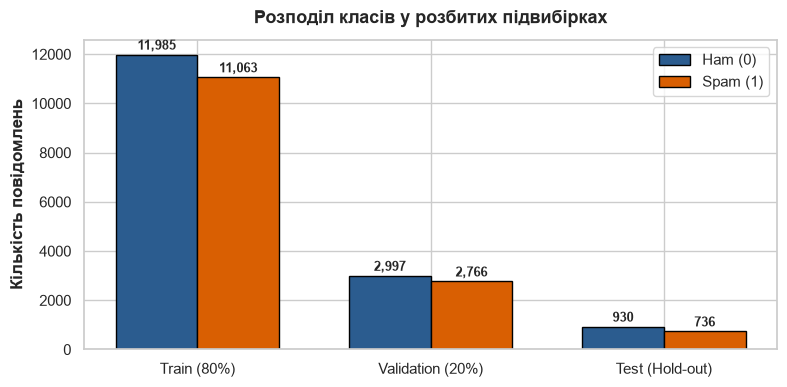

In [8]:
from sklearn.model_selection import train_test_split

train_split, val_split = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=42,
    stratify=train_clean["label"]
)

train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

splits_summary = pd.DataFrame({
    "Вибірка": ["Train (80%)", "Validation (20%)", "Test (Hold-out)"],
    "Всього листів": [len(train_split), len(val_split), len(test_clean)],
    "Ham (0)": [
        (train_split["label"] == 0).sum(),
        (val_split["label"] == 0).sum(),
        (test_clean["label"] == 0).sum()
    ],
    "Spam (1)": [
        (train_split["label"] == 1).sum(),
        (val_split["label"] == 1).sum(),
        (test_clean["label"] == 1).sum()
    ],
    "Частка Spam (%)": [
        round((train_split["label"] == 1).mean() * 100, 2),
        round((val_split["label"] == 1).mean() * 100, 2),
        round((test_clean["label"] == 1).mean() * 100, 2)
    ],
    "Сер. довжина (токенів)": [
        round(train_split["token_count"].mean(), 1),
        round(val_split["token_count"].mean(), 1),
        round(test_clean["token_count"].mean(), 1)
    ]
})

print("Характеристики сформованих сплітів даних:")
display(splits_summary)

fig, ax = plt.subplots(figsize=(8, 4))
split_names = splits_summary["Вибірка"].values
ham_vals = splits_summary["Ham (0)"].values
spam_vals = splits_summary["Spam (1)"].values

x_idx = np.arange(len(split_names))
w = 0.35

ax.bar(x_idx - w/2, ham_vals, width=w, label="Ham (0)", color=palette["ham"], edgecolor="black")
ax.bar(x_idx + w/2, spam_vals, width=w, label="Spam (1)", color=palette["spam"], edgecolor="black")
ax.set_xticks(x_idx)
ax.set_xticklabels(split_names)
ax.set_title("Розподіл класів у розбитих підвибірках", pad=12)
ax.set_ylabel("Кількість повідомлень")
ax.legend()

for i in range(len(split_names)):
    ax.annotate(f"{ham_vals[i]:,}", (x_idx[i] - w/2, ham_vals[i] + 200), ha="center", fontsize=9, weight="bold")
    ax.annotate(f"{spam_vals[i]:,}", (x_idx[i] + w/2, spam_vals[i] + 200), ha="center", fontsize=9, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "enron_split_distribution.png")
plt.show()

---
## 8. Побудова словника (Vocabulary) виключно за Train

**Правило запобігання витоку даних:**  
Словник будується **виключно за текстами навчального спліту (`train_split`)**. Тексти валідаційної та тестової вибірок не беруть участі у підрахунку частот слів. Будь-який токен у валідації чи тесті, відсутній у словнику, позначається токеном `<unk>`.

Параметри словника:
* `min_freq = 3`: відсікання рідкісних слів та випадкових опечаток.
* `max_size = 10000`: обмеження розміру словника для фіксації матриці ембеддінгів.

In [9]:
vocab = Vocabulary.build_from_texts(
    train_split["text"].tolist(),
    min_freq=3,
    max_size=10000
)

# Оцінка Out-Of-Vocabulary (OOV) rate
def calculate_unk_rate(texts, vocabulary):
    total_toks = 0
    unk_toks = 0
    for text in texts:
        tokens = tokenize_text(text)
        total_toks += len(tokens)
        unk_toks += sum(1 for t in tokens if t not in vocabulary)
    return (unk_toks / total_toks * 100) if total_toks > 0 else 0.0

train_unk = calculate_unk_rate(train_split["text"], vocab)
val_unk = calculate_unk_rate(val_split["text"], vocab)
test_unk = calculate_unk_rate(test_clean["text"], vocab)

vocab_stats = pd.DataFrame([
    {"Параметр словника": "Загальна місткість (|V|)", "Значення": len(vocab)},
    {"Параметр словника": "Поріг мінімальної частоти (min_freq)", "Значення": 3},
    {"Параметр словника": "Максимальний розмір (max_size)", "Значення": 10000},
    {"Параметр словника": "Спеціальні токени", "Значення": "<pad>=0, <unk>=1, <bos>=2, <eos>=3"},
    {"Параметр словника": "Train OOV / UNK rate (%)", "Значення": f"{train_unk:.2f}%"},
    {"Параметр словника": "Validation OOV / UNK rate (%)", "Значення": f"{val_unk:.2f}%"},
    {"Параметр словника": "Test OOV / UNK rate (%)", "Значення": f"{test_unk:.2f}%"},
])

print("Характеристики побудованого словника та оцінка OOV Rate:")
display(vocab_stats)

Характеристики побудованого словника та оцінка OOV Rate:


,Параметр словника,Значення
0,Загальна місткість (|V|),10000
1,Поріг мінімальної частоти (min_freq),3
2,Максимальний розмір (max_size),10000
3,Спеціальні токени,"<pad>=0, <unk>=1, <bos>=2, <eos>=3"
4,Train OOV / UNK rate (%),6.47%
5,Validation OOV / UNK rate (%),7.06%
6,Test OOV / UNK rate (%),7.64%


---
## 9. Векторизація послідовностей, зважування класів та серіалізація артефактів

Послідовність токенізується регулярним виразом `\w+|[^\w\s]`, відображається в числові індекси словника та доповнюється токеном `<pad>` ($ID = 0$) або усікається до довжини $L=64$.

Ваги класів для функції втрат `CrossEntropyLoss` розраховуються за формулою:
$$w_c = \frac{N}{2 \cdot N_c}$$
де $N$ — розмір навчального спліту, $N_c$ — кількість прикладів класу $c$ у навчальному спліті.

In [11]:
MAX_SEQ_LEN = 64

def prepare_tensors(df, vocabulary, max_len=64):
    input_ids_list = []
    labels_list = []
    for _, row in df.iterrows():
        tokens = tokenize_text(row["text"])
        ids = vocabulary.encode(tokens, max_len=max_len, pad_to_max=True)
        input_ids_list.append(ids)
        labels_list.append(row["label"])
    
    input_ids = torch.tensor(input_ids_list, dtype=torch.long)
    labels = torch.tensor(labels_list, dtype=torch.long)
    return input_ids, labels

train_inputs, train_labels = prepare_tensors(train_split, vocab, max_len=MAX_SEQ_LEN)
val_inputs, val_labels = prepare_tensors(val_split, vocab, max_len=MAX_SEQ_LEN)
test_inputs, test_labels = prepare_tensors(test_clean, vocab, max_len=MAX_SEQ_LEN)

sample_text = train_split["text"].iloc[0]
sample_tokens = tokenize_text(sample_text)[:10]
sample_ids = train_inputs[0, :10].tolist()

vectorization_demo = pd.DataFrame([
    {"Крок": "1. Сирий текст (фрагмент)", "Представлення": sample_text[:80] + "..."},
    {"Крок": "2. Список токенів", "Представлення": str(sample_tokens)},
    {"Крок": "3. Числові ID (перші 10)", "Представлення": str(sample_ids)},
    {"Крок": "4. Повний тензор форми [64]", "Представлення": f"torch.Tensor (довжина={len(train_inputs[0])}, PAD={train_inputs[0].eq(PAD_IDX).sum().item()})"}
])
print("Покрокова ілюстрація перетворення тексту в числовий вектор:")
display(vectorization_demo)

# Обчислення ваг класів для CrossEntropyLoss
train_class_counts = torch.bincount(train_labels)
total_train_samples = len(train_labels)
class_weights = total_train_samples / (2.0 * train_class_counts.float())

tensors_summary = pd.DataFrame([
    {
        "Підмножина": "Train",
        "Розмірність Inputs": str(list(train_inputs.shape)),
        "Розмірність Labels": str(list(train_labels.shape)),
        "Частка PAD токенів (%)": round(train_inputs.eq(PAD_IDX).float().mean().item() * 100, 2),
        "Розмір тензорів (MB)": round((train_inputs.nbytes + train_labels.nbytes) / (1024**2), 2)
    },
    {
        "Підмножина": "Validation",
        "Розмірність Inputs": str(list(val_inputs.shape)),
        "Розмірність Labels": str(list(val_labels.shape)),
        "Частка PAD токенів (%)": round(val_inputs.eq(PAD_IDX).float().mean().item() * 100, 2),
        "Розмір тензорів (MB)": round((val_inputs.nbytes + val_labels.nbytes) / (1024**2), 2)
    },
    {
        "Підмножина": "Test",
        "Розмірність Inputs": str(list(test_inputs.shape)),
        "Розмірність Labels": str(list(test_labels.shape)),
        "Частка PAD токенів (%)": round(test_inputs.eq(PAD_IDX).float().mean().item() * 100, 2),
        "Розмір тензорів (MB)": round((test_inputs.nbytes + test_labels.nbytes) / (1024**2), 2)
    }
])
print("\nЗведена характеристика підготовлених PyTorch-тензорів:")
display(tensors_summary)

print(f"\nРозраховані ваги класів для CrossEntropyLoss:")
print(f"  w_0 (Ham)  = {class_weights[0].item():.4f}")
print(f"  w_1 (Spam) = {class_weights[1].item():.4f}")

processed_payload = {
    "train_inputs": train_inputs,
    "train_labels": train_labels,
    "val_inputs": val_inputs,
    "val_labels": val_labels,
    "test_inputs": test_inputs,
    "test_labels": test_labels,
    "vocab": vocab.to_dict(),
    "class_weights": class_weights,
    "config": {
        "max_seq_len": MAX_SEQ_LEN,
        "vocab_size": len(vocab),
        "seed": 42
    }
}

save_path = PROCESSED_DATA_DIR / "enron_processed.pt"
torch.save(processed_payload, save_path)
print(f"\n[УСПІШНО] Підготовлені дані збережено у: {save_path.resolve()} (Розмір: {save_path.stat().st_size / (1024*1024):.2f} MB)")

Покрокова ілюстрація перетворення тексту в числовий вектор:


,Крок,Представлення
0,1. Сирий текст (фрагмент),cialis will help you . get erection whenever y...
1,2. Список токенів,"['cialis', 'will', 'help', 'you', '.', 'get', ..."
2,3. Числові ID (перші 10),"[894, 43, 258, 16, 4, 106, 5016, 5984, 16, 198]"
3,4. Повний тензор форми [64],"torch.Tensor (довжина=64, PAD=0)"



Зведена характеристика підготовлених PyTorch-тензорів:


,Підмножина,Розмірність Inputs,Розмірність Labels,Частка PAD токенів (%),Розмір тензорів (MB)
0,Train,"[23048, 64]",[23048],8.77,11.43
1,Validation,"[5763, 64]",[5763],8.70,2.86
2,Test,"[1666, 64]",[1666],9.68,0.83



Розраховані ваги класів для CrossEntropyLoss:
  w_0 (Ham)  = 0.9615
  w_1 (Spam) = 1.0417

[УСПІШНО] Підготовлені дані збережено у: C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\lab1\data\processed\enron_processed.pt (Розмір: 15.48 MB)


---
## 10. Підсумкові висновки етапу EDA та характеристика підготовлених даних

1. **Етапи фільтрації та розміри вибірок:**
   * Вихідний набір містив 31 716 навчальних та 2 000 тестових записів.
   * Видалено 51 порожній лист із навчальної вибірки (залишилося 31 665).
   * Видалено 2 854 точні дублікати всередині Train, що сформувало набір із 28 811 унікальних листів.
   * Під час аудиту на витік даних виявлено 334 тексти в Test, які дублювали навчальні зразки; ці приклади було вилучено з тесту, що сформувало незалежний тестовий набір з **1 666 листів**.
   * Після стратифікованого розбиття 28 811 унікальних навчальних листів отримано: **Train split** — 23 048 зразків (80%), **Validation split** — 5 763 зразки (20%).

2. **Баланс класів та ваги функції втрат:**
   * У фінальному Train split міститься 11 985 прикладів `ham` (52.00%) та 11 063 приклади `spam` (48.00%).
   * Розраховані ваги класів для `CrossEntropyLoss` становлять: $w_0 (\text{ham}) = 0.9615$, $w_1 (\text{spam}) = 1.0417$.

3. **Характеристики словника:**
   * Словник містить 10 000 токенів із порогом відсікання $min\_freq = 3$.
   * Частка невідомих токенів (OOV / UNK rate) становить 6.47% на Train, 7.06% на Validation та 7.64% на Test.

4. **Формат підготовлених даних:**
   * Усі тексти перетворено на тензори цілих чисел форми $[N, 64]$ із доповненням `<pad>` ($ID=0$).
   * Підготовлені тензори, словник та конфігурацію збережено у файлі `data/processed/enron_processed.pt` для подальшого використання у Ноутбуці №2.